# Fashion-MNIST – Exploratory Data Analysis

## Objective

The objective of this notebook is to explore the structure,
quality and statistical characteristics of the Fashion-MNIST
dataset before developing machine learning and deep learning
models.

The analysis focuses on:

- Dataset structure and dimensionality
- Data quality and duplicate observations
- Class distribution and balance
- Pixel intensity statistics
- Visual characteristics of clothing categories
- Implications for subsequent model development

Exploratory analyses are performed on the original training
dataset. The official test dataset is reserved for final
model evaluation.

## 1. Setup and Data Loading

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch

# Project configuration
RANDOM_SEED = 42

np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# Locate project root
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Output directory
FIGURES_DIR = PROJECT_ROOT / "results" / "figures" / "eda"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

# Visualization settings
sns.set_theme(style="whitegrid", palette="deep")

plt.rcParams.update(
    {
        "figure.dpi": 120,
        "savefig.dpi": 300,
        "axes.titlesize": 13,
        "axes.labelsize": 11,
    }
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Figure output directory: {FIGURES_DIR}")
print(f"PyTorch version: {torch.__version__}")

Project root: c:\Users\SUB\OneDrive - Horváth & Partner GmbH\Asztal\Github\DLProject_FashionMNIST
Figure output directory: c:\Users\SUB\OneDrive - Horváth & Partner GmbH\Asztal\Github\DLProject_FashionMNIST\results\figures\eda
PyTorch version: 2.7.1+cpu


In [2]:
from src.preprocessing.dataset import load_dataset

train_dataset, test_dataset = load_dataset()

print(f"Original training samples: {len(train_dataset):,}")
print(f"Official test samples: {len(test_dataset):,}")

Original training samples: 60,000
Official test samples: 10,000


In [3]:
# Extract raw training images and labels
images = train_dataset.data.numpy()
labels = train_dataset.targets.numpy()

# Extract class names
class_names = train_dataset.classes

print(f"Image array shape: {images.shape}")
print(f"Image data type: {images.dtype}")
print(f"Label array shape: {labels.shape}")
print(f"Number of classes: {len(class_names)}")

print("\nClass mapping:")

for class_id, class_name in enumerate(class_names):
    print(f"{class_id}: {class_name}")

Image array shape: (60000, 28, 28)
Image data type: uint8
Label array shape: (60000,)
Number of classes: 10

Class mapping:
0: T-shirt/top
1: Trouser
2: Pullover
3: Dress
4: Coat
5: Sandal
6: Shirt
7: Sneaker
8: Bag
9: Ankle boot


## 2. Dataset Overview

This section summarizes the structural characteristics of the
Fashion-MNIST dataset, including the number of observations,
image dimensionality, data types and target variable.

In [4]:
dataset_summary = pd.DataFrame(
    {
        "Characteristic": [
            "Original training samples",
            "Official test samples",
            "Total samples",
            "Image height",
            "Image width",
            "Color channels",
            "Pixels per image",
            "Image data type",
            "Label data type",
            "Number of classes",
            "Minimum pixel value",
            "Maximum pixel value",
        ],
        "Value": [
            len(train_dataset),
            len(test_dataset),
            len(train_dataset) + len(test_dataset),
            images.shape[1],
            images.shape[2],
            1,
            images.shape[1] * images.shape[2],
            str(images.dtype),
            str(labels.dtype),
            len(class_names),
            images.min(),
            images.max(),
        ],
    }
)

display(dataset_summary)

,Characteristic,Value
0,Original training samples,60000
1,Official test samples,10000
2,Total samples,70000
3,Image height,28
4,Image width,28
5,Color channels,1
6,Pixels per image,784
7,Image data type,uint8
8,Label data type,int64
9,Number of classes,10


## 3. Data Quality Assessment

The purpose of this section is to identify potential data
quality issues that may affect model training and evaluation.

The following aspects are investigated:

- Missing values
- Invalid pixel values
- Invalid class labels
- Consistency of images and labels
- Exact duplicate images
- Duplicate images with conflicting labels

### 3.1. Structural and Value Consistency Checks

In [5]:
quality_checks = pd.DataFrame(
    {
        "Check": [
            "Missing pixel values",
            "Missing labels",
            "Invalid pixel values",
            "Invalid class labels",
            "Image-label count mismatch",
            "Unexpected image dimensions",
            "Completely black images",
            "Completely white images",
        ],
        "Count": [
            np.isnan(images).sum(),
            np.isnan(labels).sum(),
            ((images < 0) | (images > 255)).sum(),
            (~np.isin(labels, np.arange(len(class_names)))).sum(),
            abs(len(images) - len(labels)),
            int(images.shape[1:] != (28, 28)),
            np.all(images == 0, axis=(1, 2)).sum(),
            np.all(images == 255, axis=(1, 2)).sum(),
        ],
    }
)

quality_checks["Status"] = np.where(
    quality_checks["Count"] == 0,
    "OK",
    "Review required",
)

display(quality_checks)

,Check,Count,Status
0,Missing pixel values,0,OK
1,Missing labels,0,OK
2,Invalid pixel values,0,OK
3,Invalid class labels,0,OK
4,Image-label count mismatch,0,OK
5,Unexpected image dimensions,0,OK
6,Completely black images,0,OK
7,Completely white images,0,OK


### 3.2. Exact Duplicate Images

Exact duplicate images are identified by comparing their raw
pixel representations.

Duplicate observations may reduce the effective diversity of
the dataset and potentially introduce data leakage if identical
images are assigned to different dataset splits.

In [6]:
import hashlib

image_hashes = [hashlib.sha256(image.tobytes()).hexdigest() for image in images]

image_metadata = pd.DataFrame(
    {
        "image_index": np.arange(len(images)),
        "image_hash": image_hashes,
        "label": labels,
    }
)

hash_counts = image_metadata["image_hash"].value_counts()

duplicate_groups = hash_counts[hash_counts > 1]

duplicate_summary = pd.DataFrame(
    {
        "Characteristic": [
            "Total images",
            "Unique images",
            "Duplicate image groups",
            "Images belonging to duplicate groups",
            "Redundant duplicate images",
        ],
        "Count": [
            len(images),
            len(hash_counts),
            len(duplicate_groups),
            duplicate_groups.sum(),
            len(images) - len(hash_counts),
        ],
    }
)

display(duplicate_summary)

,Characteristic,Count
0,Total images,60000
1,Unique images,60000
2,Duplicate image groups,0
3,Images belonging to duplicate groups,0
4,Redundant duplicate images,0


### 3.3. Duplicate Images with Conflicting Labels

Identical images associated with different class labels may
indicate inconsistent annotation and introduce ambiguity
into the classification task.

In [7]:
label_counts_per_image = image_metadata.groupby("image_hash")["label"].nunique()

conflicting_hashes = label_counts_per_image[label_counts_per_image > 1].index

conflicting_images = image_metadata[image_metadata["image_hash"].isin(conflicting_hashes)]

conflict_summary = pd.DataFrame(
    {
        "Characteristic": [
            "Duplicate groups with conflicting labels",
            "Images affected by conflicting labels",
        ],
        "Count": [
            len(conflicting_hashes),
            len(conflicting_images),
        ],
    }
)

display(conflict_summary)

,Characteristic,Count
0,Duplicate groups with conflicting labels,0
1,Images affected by conflicting labels,0


### 3.4. Key Findings

All structural and value consistency checks were passed.

- No missing or invalid pixel values were identified.
- All class labels are within the expected range.
- All images have the expected dimensions.
- No completely black or white images were detected.
- All 60,000 training images are unique.
- No exact duplicates with conflicting labels were found.

Based on these checks, no data cleaning or duplicate
removal is required.

However, these results do not rule out near-duplicate
images or incorrectly annotated individual samples.

## 4. Class Distribution

This section investigates the distribution of clothing
categories in the original training dataset.

The analysis evaluates class frequencies, relative
frequencies and potential class imbalance, which may
influence model training and evaluation.

In [8]:
class_distribution = pd.DataFrame(
    {
        "Class ID": np.arange(len(class_names)),
        "Class": class_names,
        "Frequency": np.bincount(
            labels,
            minlength=len(class_names),
        ),
    }
)

class_distribution["Relative Frequency (%)"] = class_distribution["Frequency"] / len(labels) * 100

display(class_distribution)

min_frequency = class_distribution["Frequency"].min()
max_frequency = class_distribution["Frequency"].max()

imbalance_ratio = max_frequency / min_frequency

print(f"Minimum class frequency: {min_frequency:,}")
print(f"Maximum class frequency: {max_frequency:,}")
print(f"Imbalance ratio: {imbalance_ratio:.2f}")

,Class ID,Class,Frequency,Relative Frequency (%)
0,0,T-shirt/top,6000,10.0
1,1,Trouser,6000,10.0
2,2,Pullover,6000,10.0
3,3,Dress,6000,10.0
4,4,Coat,6000,10.0
5,5,Sandal,6000,10.0
6,6,Shirt,6000,10.0
7,7,Sneaker,6000,10.0
8,8,Bag,6000,10.0
9,9,Ankle boot,6000,10.0


Minimum class frequency: 6,000
Maximum class frequency: 6,000
Imbalance ratio: 1.00


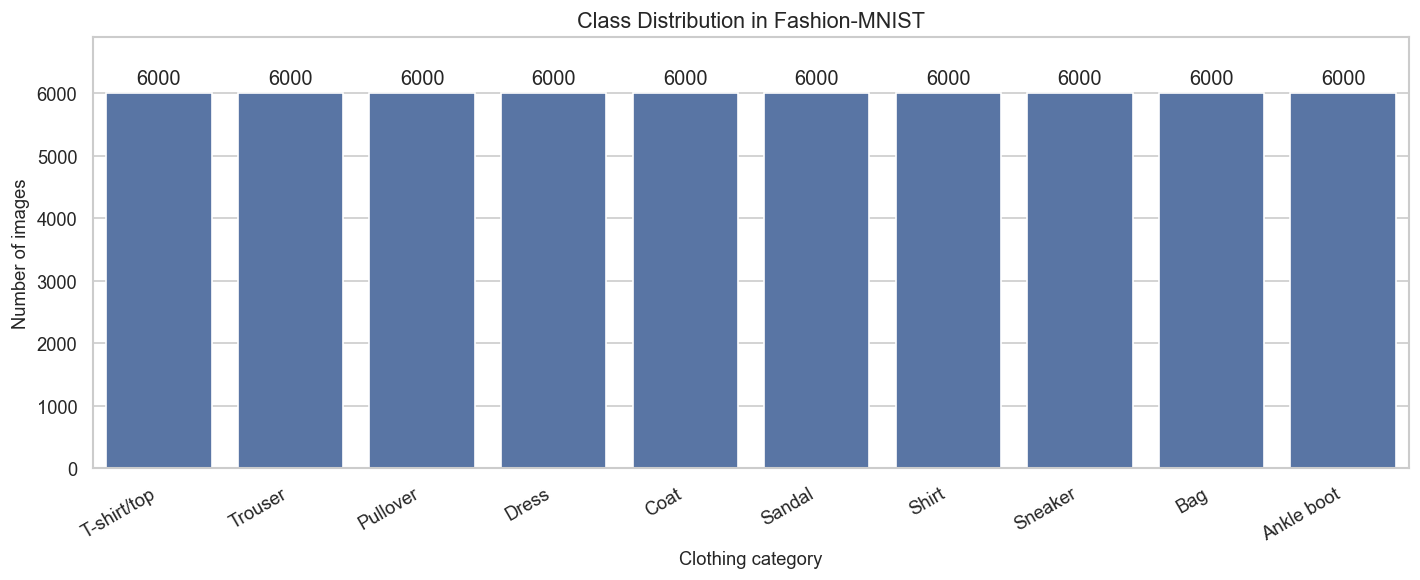

In [9]:
fig, ax = plt.subplots(figsize=(12, 5))

sns.barplot(
    data=class_distribution,
    x="Class",
    y="Frequency",
    color="#4C72B0",
    ax=ax,
)

ax.set_title("Class Distribution in Fashion-MNIST")
ax.set_xlabel("Clothing category")
ax.set_ylabel("Number of images")
ax.set_ylim(0, max_frequency * 1.15)

ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

plt.xticks(rotation=30, ha="right")
plt.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_distribution.png",
    bbox_inches="tight",
)

plt.show()

### Key Findings

The original training dataset is perfectly balanced,
with 6,000 images per class and an imbalance ratio of 1.00.

Therefore, class balancing techniques such as oversampling,
undersampling or frequency-based class weighting are not
required for the baseline models.

Stratified sampling is recommended when creating the
training and validation subsets to preserve the original
class distribution.

## 5. Pixel Intensity Analysis

Pixel intensity statistics provide insights into the
brightness, variability and sparsity of the image data.

The analysis examines both the overall pixel intensity
distribution and differences between clothing categories.

### 5.1. Overall Pixel Statistics

In [10]:
pixel_summary = pd.DataFrame(
    {
        "Statistic": [
            "Number of pixels",
            "Minimum",
            "Maximum",
            "Mean",
            "Standard deviation",
            "Median",
            "25th percentile",
            "75th percentile",
            "Zero-valued pixels (%)",
            "Maximum-intensity pixels (%)",
        ],
        "Value": [
            images.size,
            images.min(),
            images.max(),
            images.mean(),
            images.std(),
            np.median(images),
            np.percentile(images, 25),
            np.percentile(images, 75),
            (images == 0).mean() * 100,
            (images == 255).mean() * 100,
        ],
    }
)

display(pixel_summary.style.format({"Value": "{:,.4f}"}))

,Statistic,Value
0,Number of pixels,"47,040,000.0000"
1,Minimum,0.0000
2,Maximum,255.0000
3,Mean,72.9404
4,Standard deviation,90.0212
5,Median,0.0000
6,25th percentile,0.0000
7,75th percentile,163.0000
8,Zero-valued pixels (%),50.2051
9,Maximum-intensity pixels (%),0.8059


### 5.2. Pixel Intensity Distribution

The histogram illustrates the frequency of grayscale
pixel intensities across the original training dataset.

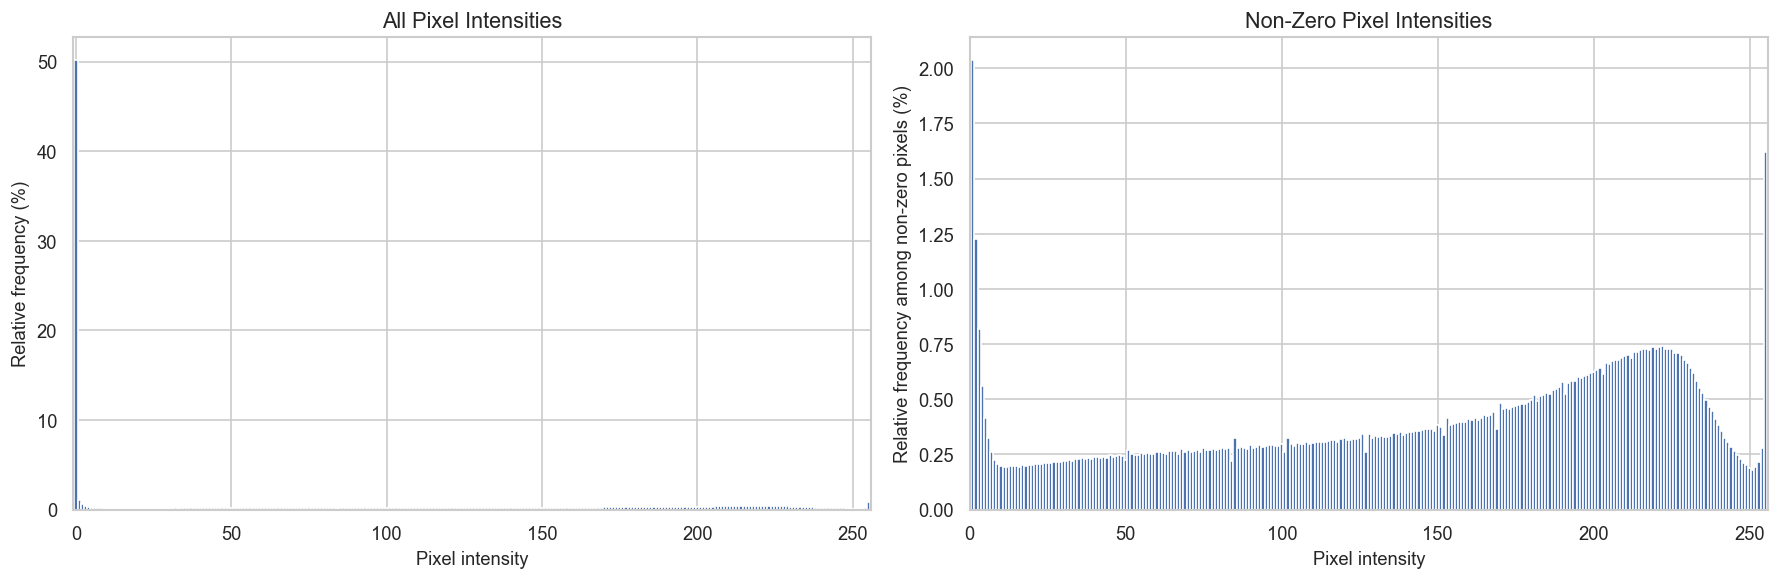

In [11]:
pixel_counts = np.bincount(
    images.ravel(),
    minlength=256,
)

pixel_relative_frequency = pixel_counts / images.size * 100

nonzero_relative_frequency = pixel_counts[1:] / pixel_counts[1:].sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Overall pixel distribution
axes[0].bar(
    np.arange(256),
    pixel_relative_frequency,
    width=1,
    color="#4C72B0",
)

axes[0].set_title("All Pixel Intensities")
axes[0].set_xlabel("Pixel intensity")
axes[0].set_ylabel("Relative frequency (%)")
axes[0].set_xlim(-1, 256)

# Conditional distribution of non-zero pixels
axes[1].bar(
    np.arange(1, 256),
    nonzero_relative_frequency,
    width=1,
    color="#4C72B0",
)

axes[1].set_title("Non-Zero Pixel Intensities")
axes[1].set_xlabel("Pixel intensity")
axes[1].set_ylabel("Relative frequency among non-zero pixels (%)")
axes[1].set_xlim(0, 256)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "pixel_intensity_distribution.png",
    bbox_inches="tight",
)

plt.show()

### 5.3. Class-Level Pixel Statistics

Pixel intensity statistics are calculated separately
for each clothing category to identify differences
in brightness, variability and background coverage.

In [12]:
class_pixel_stats = []

for class_id, class_name in enumerate(class_names):
    class_images = images[labels == class_id]

    class_pixel_stats.append(
        {
            "Class": class_name,
            "Mean intensity": class_images.mean(),
            "Standard deviation": class_images.std(),
            "Zero-valued pixels (%)": ((class_images == 0).mean() * 100),
            "Maximum-intensity pixels (%)": ((class_images == 255).mean() * 100),
        }
    )

class_pixel_stats = pd.DataFrame(class_pixel_stats)

display(class_pixel_stats.round(2))

,Class,Mean intensity,Standard deviation,Zero-valued pixels (%),Maximum-intensity pixels (%)
0,T-shirt/top,83.03,89.44,40.59,0.59
1,Trouser,56.84,87.60,65.13,1.23
2,Pullover,96.06,91.46,35.13,1.28
3,Dress,66.02,90.33,57.21,0.85
4,Coat,98.26,95.96,39.83,0.97
5,Sandal,34.87,67.09,67.89,0.43
6,Shirt,84.61,86.52,37.09,0.66
7,Sneaker,42.76,75.17,66.21,0.43
8,Bag,90.16,93.14,41.44,0.76
9,Ankle boot,76.81,94.49,51.55,0.86


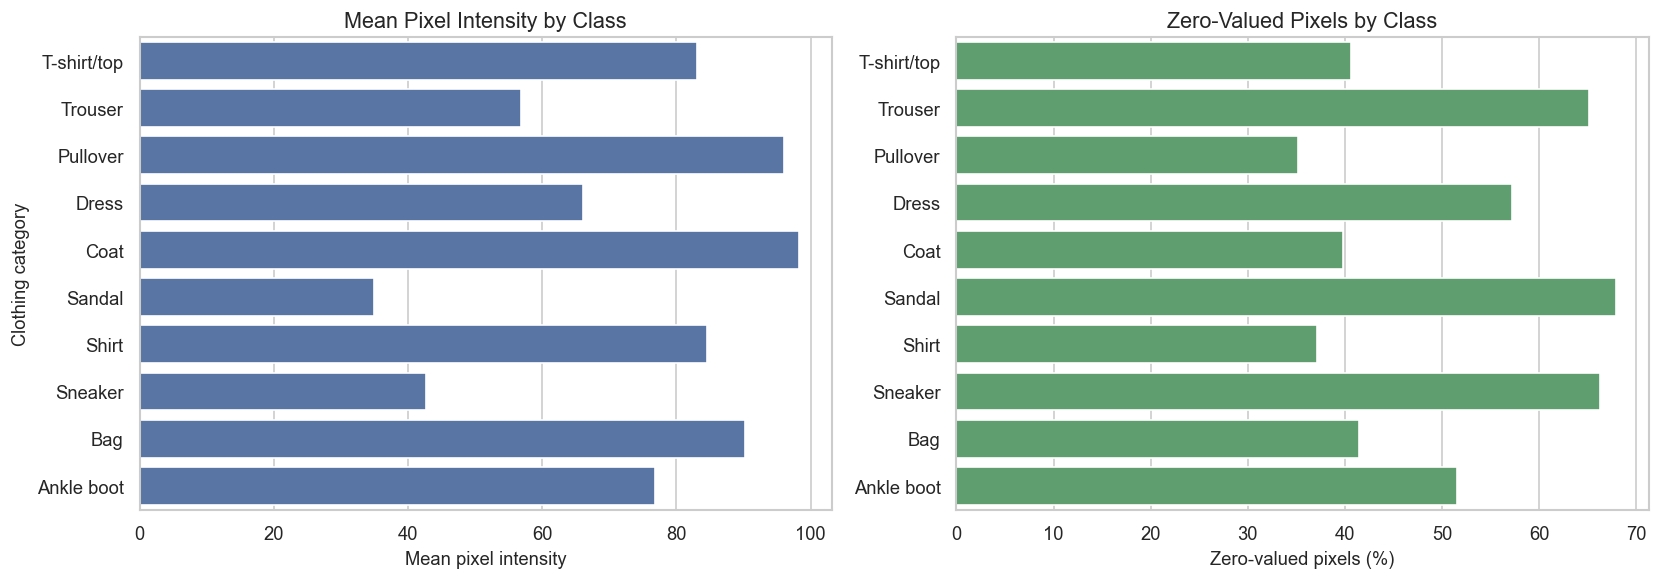

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=class_pixel_stats,
    y="Class",
    x="Mean intensity",
    color="#4C72B0",
    ax=axes[0],
)

axes[0].set_title("Mean Pixel Intensity by Class")
axes[0].set_xlabel("Mean pixel intensity")
axes[0].set_ylabel("Clothing category")

sns.barplot(
    data=class_pixel_stats,
    y="Class",
    x="Zero-valued pixels (%)",
    color="#55A868",
    ax=axes[1],
)

axes[1].set_title("Zero-Valued Pixels by Class")
axes[1].set_xlabel("Zero-valued pixels (%)")
axes[1].set_ylabel("")

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_pixel_statistics.png",
    bbox_inches="tight",
)

plt.show()

### 5.4. Key Findings

The dataset contains approximately 47 million pixels,
with intensity values ranging from 0 to 255.

- The mean pixel intensity is 72.94, with a standard
  deviation of 90.02.
- Approximately 50.21% of all pixels have zero intensity,
  reflecting the predominantly black image backgrounds.
- Pixel intensity statistics differ substantially across
  clothing categories.
- Coats and pullovers have relatively high mean intensities,
  whereas sandals and sneakers contain a higher proportion
  of zero-valued pixels.
- Similar global pixel statistics across certain categories
  suggest that spatial features may be important for
  accurate classification.

These observations support investigating models that
can effectively capture spatial image characteristics.

Any data-dependent normalization parameters must be
estimated exclusively from the final training subset.

## 6. Image Exploration

This section explores the visual characteristics of
the clothing categories using representative sample
images and class-level mean images.

The objective is to identify within-class variability,
between-class similarities and spatial patterns that
may influence classification performance.

### 6.1. Random Sample Images by Class

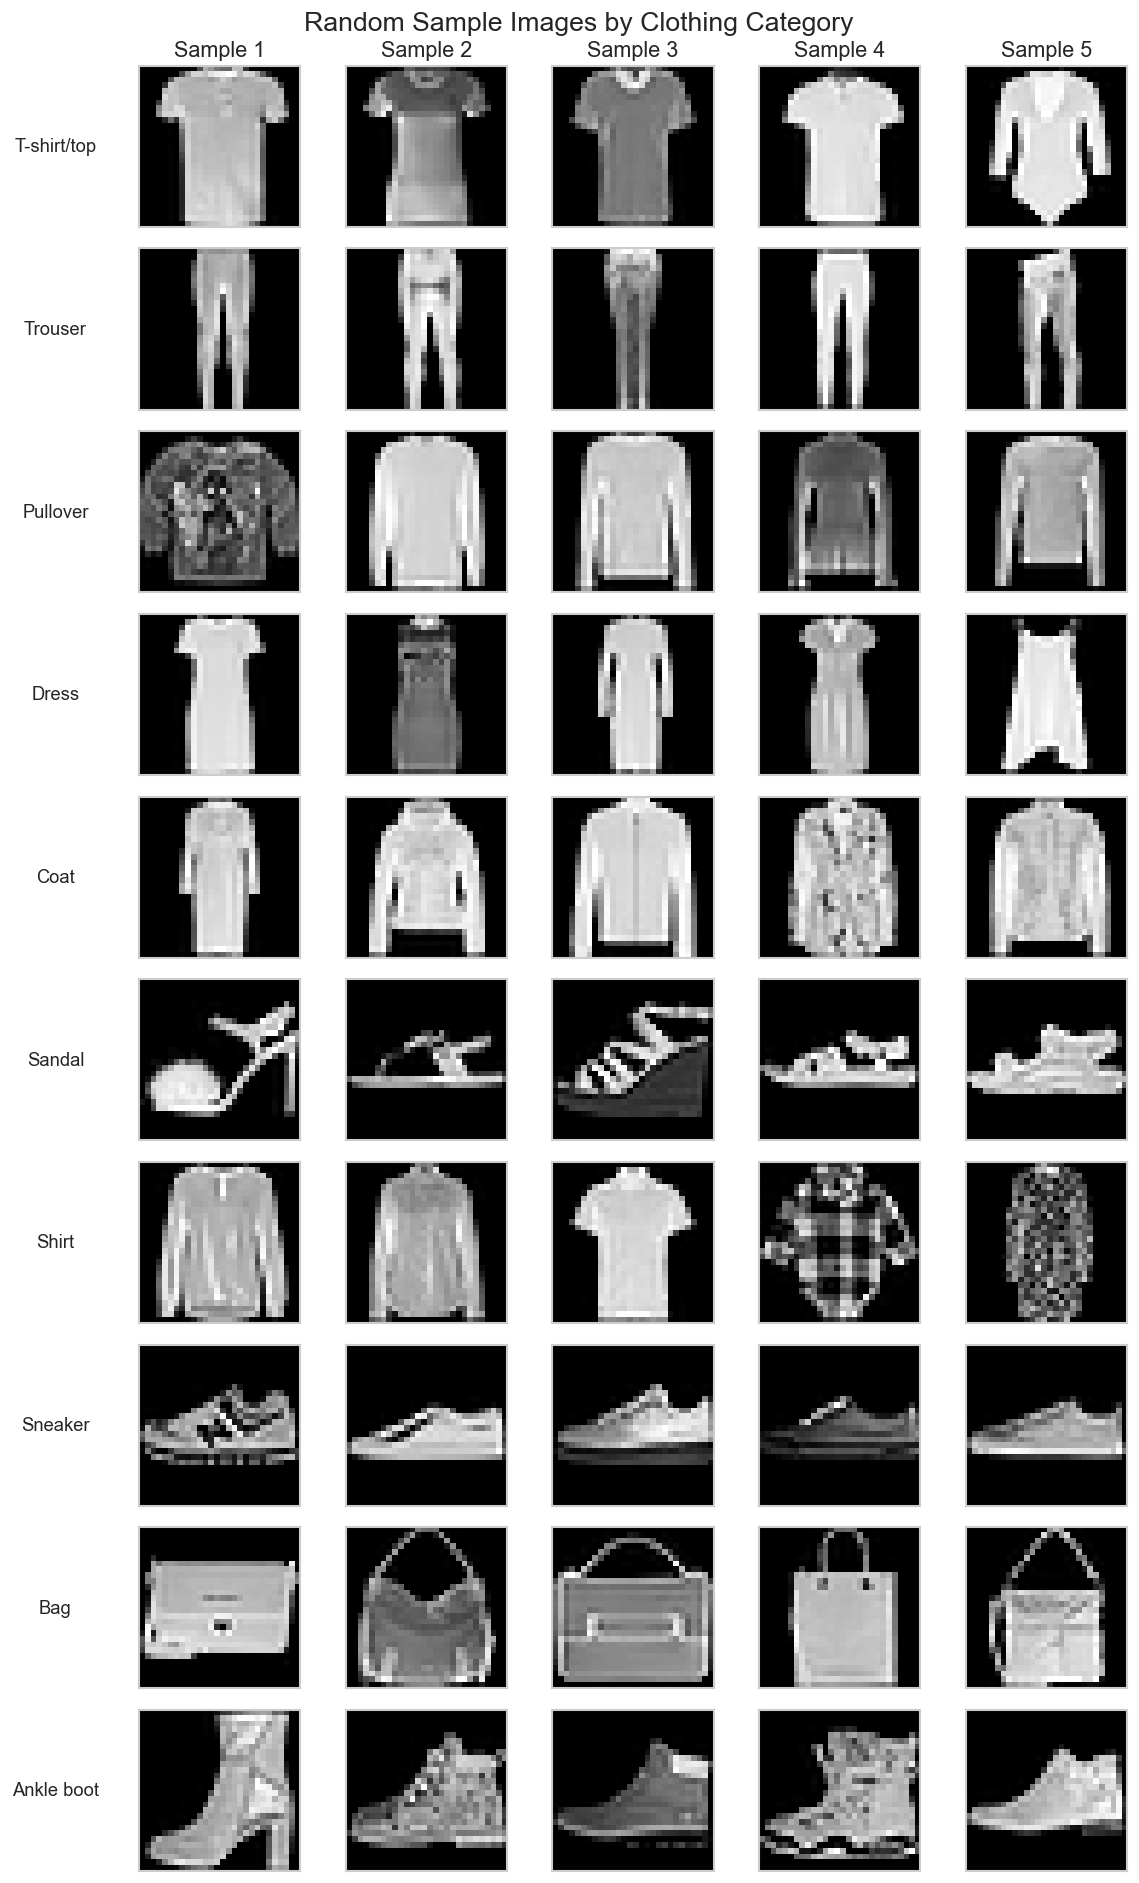

In [14]:
N_SAMPLES_PER_CLASS = 5

rng = np.random.default_rng(RANDOM_SEED)

fig, axes = plt.subplots(
    len(class_names),
    N_SAMPLES_PER_CLASS,
    figsize=(10, 16),
)

for class_id, class_name in enumerate(class_names):
    class_indices = np.where(labels == class_id)[0]

    sample_indices = rng.choice(
        class_indices,
        size=N_SAMPLES_PER_CLASS,
        replace=False,
    )

    for col, image_index in enumerate(sample_indices):
        ax = axes[class_id, col]

        ax.imshow(
            images[image_index],
            cmap="gray",
            vmin=0,
            vmax=255,
        )

        ax.set_xticks([])
        ax.set_yticks([])
        ax.grid(False)

        if col == 0:
            ax.set_ylabel(
                class_name,
                rotation=0,
                labelpad=50,
                va="center",
            )

        if class_id == 0:
            ax.set_title(f"Sample {col + 1}")

fig.suptitle(
    "Random Sample Images by Clothing Category",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "sample_images.png",
    bbox_inches="tight",
)

plt.show()

### 6.2. Class-Level Mean Images

Mean images are calculated by averaging pixel
intensities at each spatial position across all
images belonging to the same clothing category.

This visualization highlights characteristic shapes,
spatial patterns and similarities between classes.

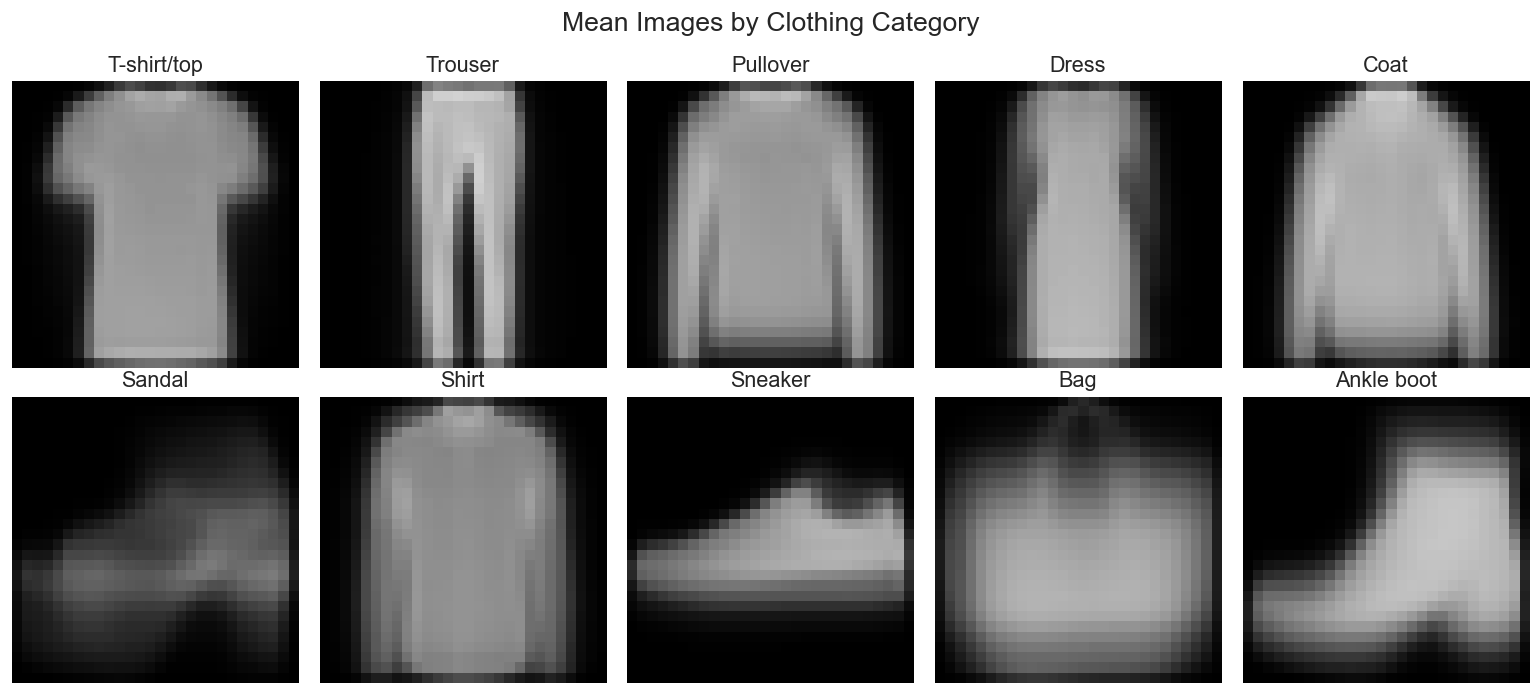

In [15]:
class_mean_images = np.stack(
    [images[labels == class_id].mean(axis=0) for class_id in range(len(class_names))]
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(13, 6),
)

for class_id, ax in enumerate(axes.ravel()):
    ax.imshow(
        class_mean_images[class_id],
        cmap="gray",
        vmin=0,
        vmax=255,
    )

    ax.set_title(class_names[class_id])
    ax.axis("off")

fig.suptitle(
    "Mean Images by Clothing Category",
    fontsize=16,
)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "class_mean_images.png",
    bbox_inches="tight",
)

plt.show()

## 7. Key Findings and Modeling Implications

The exploratory data analysis provides the following
insights into the original Fashion-MNIST training dataset.

### Data Quality

All 60,000 images are unique, and no missing values,
invalid labels or structural inconsistencies were identified.

No data cleaning or exact duplicate removal is required
based on the performed checks.

### Class Distribution

The dataset is perfectly balanced, with 6,000 images
per class. Class balancing techniques are therefore
not required for the baseline experiments.

Stratified sampling is recommended for the shared
training and validation split.

### Pixel Intensity Characteristics

Approximately 50.21% of all pixels have zero intensity.
Substantial differences in mean pixel intensity and
background coverage were observed across clothing classes.

### Visual Characteristics

Global pixel statistics are similar for some clothing
categories. Spatial patterns and local image features
may therefore contribute to more accurate classification.

### Implications for Model Development

- Preserve the shared dataset and class distribution.
- Scale pixel intensities consistently across models.
- Estimate data-dependent normalization parameters
  exclusively from the final training subset.
- Investigate both flattened pixel representations
  and spatial image representations.
- Evaluate models using accuracy, macro F1-score
  and class-level confusion matrices.
- Investigate potential classification difficulties
  between visually similar clothing categories.

The official test dataset remains reserved for final
model evaluation.